<a href="https://colab.research.google.com/github/gezahagnhailegnaw71-a11y/numerical_practice/blob/main/Secant_Method_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Secant Method
**Numerical Analysis · Lab · Final version**

**Problem.** Solve $f(x)=0$.

**Idea.** Newton's method needs the derivative $f'(x)$. Often we do not have it. The secant method replaces the **tangent** by the **secant line** through the last **two** points $(x_{k-1},f(x_{k-1}))$ and $(x_k,f(x_k))$. Its slope approximates $f'(x_k)$:

$$f'(x_k)\approx\frac{f(x_k)-f(x_{k-1})}{x_k-x_{k-1}}
\qquad\Longrightarrow\qquad
\boxed{\,x_{k+1}=x_k-f(x_k)\,\frac{x_k-x_{k-1}}{f(x_k)-f(x_{k-1})}\,}$$

Stop when $\lvert x_{k+1}-x_k\rvert<\text{tol}$.

| | Secant |
|---|---|
| Needs | $f$ and **two** starting guesses $x_0, x_1$ (no derivative, no sign change needed) |
| Speed | superlinear, order $\approx1.618$ (golden ratio): almost as fast as Newton |
| Cost | only **one** new value of $f$ per step |
| Danger | $f(x_k)=f(x_{k-1})$ (horizontal secant); bad starting points can diverge |

**Compare with false position:** the formula looks the same, but false position always keeps a **bracket** with a sign change; the secant method simply uses the **last two** points.

## Step 1: Import

In [ ]:
import math

## Step 2: Notation (quick reminder)
The **full notation guide** (math symbols, the meaning of `f`, all format codes, how to build a table) is in **Bisection_Method_Final.ipynb**.

| Format code | Meaning | Example |
|---|---|---|
| `f"{x:>14.10f}"` | right aligned, width 14, 10 decimals | `  1.3652300134` |
| `f"{x:>12.2e}"` | scientific notation | `    1.09e-13` |
| `f"{n:>5d}"` | whole number, width 5 | `    7` |

### New in the secant method
| Notation | Meaning |
|---|---|
| `x0, x1` | the **two** starting guesses |
| `x2 = x1 - f(x1) * (x1 - x0) / (f(x1) - f(x0))` | one secant step. **Brackets matter!** |
| `x0, x1 = x1, x2` | move forward: forget the oldest point. Python changes **both** names at the same time |
| `if f(x1) == f(x0):` | horizontal secant line: it never meets the $x$-axis, we must stop |
| `abs(x2 - x1) < tol` | two answers almost the same, so **stop** |
| `return None, table` | `None` means "no answer" (the method failed) |

## Step 3: Write the functions
### 3a. `print_table`: prints the steps as a table
We write the printing **once**, so every version of the method can use it.

In [ ]:
COLUMNS = ["step", "x_{k-1}", "x_k", "x_{k+1}", "f(x_{k+1})", "|step|"]

def print_table(table):
    # header, line, one row for each step, line
    print(f"{'step':>5} {'x_k-1':>14} {'x_k':>14} {'x_k+1':>14} {'f(x_k+1)':>12} {'|step|':>12}")
    print("-" * 76)
    for row in table:
        print(f"{row[0]:>5d} {row[1]:>14.10f} {row[2]:>14.10f} {row[3]:>14.10f} {row[4]:>12.2e} {row[5]:>12.2e}")
    print("-" * 76)

### 3b. `secant` with a `for` loop
The loop runs at most `max_iter` times and stops early with `break` when two answers are almost the same.

In [ ]:
def secant(f, x0, x1, tol=1e-6, max_iter=50, show=True):
    # f       : the function in f(x) = 0
    # x0, x1  : two starting guesses
    # tol     : stop when two answers differ by less than tol
    # max_iter: safety limit on the number of steps
    # show    : True = print the table

    table = []                                     # one row for each step
    converged = False

    for step in range(1, max_iter + 1):            # at most max_iter steps
        f0, f1 = f(x0), f(x1)

        if f1 == f0:                               # horizontal secant line: cannot continue
            if show:
                print(f"Stopped at step {step}: f(x0) = f(x1) (horizontal secant line)")
            return None, table

        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)       # secant step
        table.append([step, x0, x1, x2, f(x2), abs(x2 - x1)])   # save this row

        if abs(x2 - x1) < tol:                     # two answers almost the same: stop
            converged = True
            x1 = x2
            break
        x0, x1 = x1, x2                            # move forward: forget the oldest point

    if show:
        print_table(table)
        if converged:
            print(f"Root = {x1:.10f}   (found in {step} steps)\n")
        else:
            print(f"WARNING: no convergence after {max_iter} steps. Last value = {x1}\n")

    return x1, table

## Step 4: Example 1 — $x^3+4x^2-10=0$, $\;x_0=1,\ x_1=2$
No derivative is needed: only $f$.

In [ ]:
def f1(x):
    return x**3 + 4*x**2 - 10

root, table = secant(f1, 1, 2)

 step          x_k-1            x_k          x_k+1     f(x_k+1)       |step|
----------------------------------------------------------------------------
    1   1.0000000000   2.0000000000   1.2631578947    -1.60e+00     7.37e-01
    2   2.0000000000   1.2631578947   1.3388278388    -4.30e-01     7.57e-02
    3   1.2631578947   1.3388278388   1.3666163947     2.29e-02     2.78e-02
    4   1.3388278388   1.3666163947   1.3652119026    -2.99e-04     1.40e-03
    5   1.3666163947   1.3652119026   1.3652300011    -2.03e-07     1.81e-05
    6   1.3652119026   1.3652300011   1.3652300134     1.80e-12     1.23e-08
----------------------------------------------------------------------------
Root = 1.3652300134   (found in 6 steps)



Look at the column `|step|`: it falls slowly at first, then very fast. The secant method is **superlinear** (order $\approx 1.618$): between bisection (order 1) and Newton (order 2).

## Step 5: More examples
We only change `f(x)` and the two starting guesses.

In [ ]:
# Example 2:  cos(x) - x = 0,  x0 = 0, x1 = 1
def f2(x):
    return math.cos(x) - x

root, table = secant(f2, 0, 1)

 step          x_k-1            x_k          x_k+1     f(x_k+1)       |step|
----------------------------------------------------------------------------
    1   0.0000000000   1.0000000000   0.6850733573     8.93e-02     3.15e-01
    2   1.0000000000   0.6850733573   0.7362989976     4.66e-03     5.12e-02
    3   0.6850733573   0.7362989976   0.7391193619    -5.73e-05     2.82e-03
    4   0.7362989976   0.7391193619   0.7390851121     3.53e-08     3.42e-05
    5   0.7391193619   0.7390851121   0.7390851332     2.67e-13     2.11e-08
----------------------------------------------------------------------------
Root = 0.7390851332   (found in 5 steps)



In [ ]:
# Example 3:  x^2 - 2 = 0,  x0 = 1, x1 = 2   (the root is the square root of 2)
def f3(x):
    return x**2 - 2

root, table = secant(f3, 1, 2)

 step          x_k-1            x_k          x_k+1     f(x_k+1)       |step|
----------------------------------------------------------------------------
    1   1.0000000000   2.0000000000   1.3333333333    -2.22e-01     6.67e-01
    2   2.0000000000   1.3333333333   1.4000000000    -4.00e-02     6.67e-02
    3   1.3333333333   1.4000000000   1.4146341463     1.19e-03     1.46e-02
    4   1.4000000000   1.4146341463   1.4142114385    -6.01e-06     4.23e-04
    5   1.4146341463   1.4142114385   1.4142135621    -8.93e-10     2.12e-06
    6   1.4142114385   1.4142135621   1.4142135624     8.88e-16     3.16e-10
----------------------------------------------------------------------------
Root = 1.4142135624   (found in 6 steps)



In [ ]:
# Example 4:  x^3 - x - 2 = 0,  x0 = 1, x1 = 2
def f4(x):
    return x**3 - x - 2

root, table = secant(f4, 1, 2)

 step          x_k-1            x_k          x_k+1     f(x_k+1)       |step|
----------------------------------------------------------------------------
    1   1.0000000000   2.0000000000   1.3333333333    -9.63e-01     6.67e-01
    2   2.0000000000   1.3333333333   1.4626865672    -3.33e-01     1.29e-01
    3   1.3333333333   1.4626865672   1.5311694321     5.86e-02     6.85e-02
    4   1.4626865672   1.5311694321   1.5209264205    -2.69e-03     1.02e-02
    5   1.5311694321   1.5209264205   1.5213763167    -2.02e-05     4.50e-04
    6   1.5209264205   1.5213763167   1.5213797080     7.02e-09     3.39e-06
    7   1.5213763167   1.5213797080   1.5213797068    -1.84e-14     1.18e-09
----------------------------------------------------------------------------
Root = 1.5213797068   (found in 7 steps)



In [ ]:
# Example 5:  e^x - 3x = 0,  x0 = 0, x1 = 1
def f5(x):
    return math.exp(x) - 3*x

root, table = secant(f5, 0, 1)

 step          x_k-1            x_k          x_k+1     f(x_k+1)       |step|
----------------------------------------------------------------------------
    1   0.0000000000   1.0000000000   0.7802027171    -1.59e-01     2.20e-01
    2   1.0000000000   0.7802027171   0.4966786101     1.53e-01     2.84e-01
    3   0.7802027171   0.4966786101   0.6359522470    -1.90e-02     1.39e-01
    4   0.4966786101   0.6359522470   0.6205603912    -1.71e-03     1.54e-02
    5   0.6359522470   0.6205603912   0.6190402695     2.40e-05     1.52e-03
    6   0.6205603912   0.6190402695   0.6190613124    -2.93e-08     2.10e-05
    7   0.6190402695   0.6190613124   0.6190612867    -5.01e-13     2.56e-08
----------------------------------------------------------------------------
Root = 0.6190612867   (found in 7 steps)



**The starting points do NOT need a sign change.** Here $f(1.5)$ and $f(2)$ are both positive, but the secant method still finds the root (bisection and false position could not even start):

In [ ]:
print("f(1.5) =", f1(1.5), "  f(2) =", f1(2))
root, table = secant(f1, 1.5, 2)

f(1.5) = 2.375   f(2) = 14
 step          x_k-1            x_k          x_k+1     f(x_k+1)       |step|
----------------------------------------------------------------------------
    1   1.5000000000   2.0000000000   1.3978494624     5.47e-01     6.02e-01
    2   2.0000000000   1.3978494624   1.3733516882     1.35e-01     2.45e-02
    3   1.3978494624   1.3733516882   1.3653579795     2.11e-03     7.99e-03
    4   1.3733516882   1.3653579795   1.3652305214     8.39e-06     1.27e-04
    5   1.3653579795   1.3652305214   1.3652300134     5.26e-10     5.08e-07
----------------------------------------------------------------------------
Root = 1.3652300134   (found in 5 steps)



## Step 6: When the secant method fails
**Failure 1: horizontal secant line.** $f(x)=x^2-1$ with $x_0=-0.5$, $x_1=0.5$: $f(x_0)=f(x_1)$, so the line never meets the axis.

In [ ]:
root, table = secant(lambda x: x**2 - 1, -0.5, 0.5)

Stopped at step 1: f(x0) = f(x1) (horizontal secant line)


**Failure 2: bad starting points diverge.** $f(x)=\arctan x$ (root $0$) with $x_0=2$, $x_1=3$: the points jump further and further away.

In [ ]:
def f6(x):
    return math.atan(x)

root, table = secant(f6, 2, 3, max_iter=6)
print("From x0 = 1, x1 = 1.5 instead it converges:")
root, table = secant(f6, 1, 1.5)

 step          x_k-1            x_k          x_k+1     f(x_k+1)       |step|
----------------------------------------------------------------------------
    1   2.0000000000   3.0000000000  -5.8024785002    -1.40e+00     8.80e+00
    2   3.0000000000  -5.8024785002  -1.1502295666    -8.55e-01     4.65e+00
    3  -5.8024785002  -1.1502295666   6.1498001681     1.41e+00     7.30e+00
    4  -1.1502295666   6.1498001681   1.6062013124     1.01e+00     4.54e+00
    5   6.1498001681   1.6062013124 -10.0372253586    -1.47e+00     1.16e+01
    6   1.6062013124 -10.0372253586  -3.1437502912    -1.26e+00     6.89e+00
----------------------------------------------------------------------------

From x0 = 1, x1 = 1.5 instead it converges:
 step          x_k-1            x_k          x_k+1     f(x_k+1)       |step|
----------------------------------------------------------------------------
    1   1.0000000000   1.5000000000  -0.9894017981    -7.80e-01     2.49e+00
    2   1.5000000000  -0.989401

## Step 7: Secant vs Newton
Same equations and tolerance. Newton needs the derivative and **two** evaluations per step ($f$ and $f'$); secant needs **one** ($f$).
(The short `newton` below is only for this comparison; see the Newton notebook.)

In [ ]:
def newton(f, df, x0, tol=1e-10, max_iter=50):
    x = x0
    for step in range(1, max_iter + 1):
        x_new = x - f(x) / df(x)
        if abs(x_new - x) < tol:
            return x_new, step
        x = x_new
    return x, max_iter

problems = [
    ("x^3 + 4x^2 - 10", f1, lambda x: 3*x**2 + 8*x,      1, 2),
    ("cos(x) - x",      f2, lambda x: -math.sin(x) - 1,  0, 1),
    ("x^2 - 2",         f3, lambda x: 2*x,               1, 2),
    ("x^3 - x - 2",     f4, lambda x: 3*x**2 - 1,        1, 2),
    ("e^x - 3x",        f5, lambda x: math.exp(x) - 3,   0, 1),
]

print(f"{'equation':<16} {'secant root':>14} {'steps':>6} {'f-evals':>8}   {'Newton root':>14} {'steps':>6} {'evals':>6}")
print("-" * 80)
for name, f, df, a, b in problems:
    rs, ts = secant(f, a, b, tol=1e-10, show=False)
    rn, sn = newton(f, df, b, tol=1e-10)
    print(f"{name:<16} {rs:>14.10f} {len(ts):>6d} {len(ts) + 1:>8d}   {rn:>14.10f} {sn:>6d} {2 * sn:>6d}")

equation            secant root  steps  f-evals      Newton root  steps  evals
--------------------------------------------------------------------------------
x^3 + 4x^2 - 10    1.3652300134      7        8     1.3652300134      6     12
cos(x) - x         0.7390851332      6        7     0.7390851332      5     10
x^2 - 2            1.4142135624      7        8     1.4142135624      5     10
x^3 - x - 2        1.5213797068      8        9     1.5213797068      6     12
e^x - 3x           0.6190612867      8        9     0.6190612867      7     14


Newton usually needs **fewer steps**, but the secant method often needs **fewer function evaluations**, and it does not need $f'$. (Our `secant` function calls `f` a few extra times to keep the code simple; a careful version re-uses $f(x_k)$ and needs exactly one new value per step, which is what the `f-evals` column counts.)

## Step 8: Animations — watch the secant lines
Each frame draws **one** secant line through the last two points, extended down to the $x$-axis at the new point $x_{k+1}$. Press ▶.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
plt.rcParams["animation.embed_limit"] = 40          # allow bigger animations in the notebook

def curve_points(f, xmin, xmax, n=400):
    # x and y values of the curve y = f(x) for plotting (nan where f cannot be computed)
    xs = [xmin + (xmax - xmin) * i / n for i in range(n + 1)]
    ys = []
    for x in xs:
        try:
            ys.append(f(x))
        except (ValueError, OverflowError, ZeroDivisionError):
            ys.append(float("nan"))
    return xs, ys

def animate_secant(f, x0, x1, xmin, xmax, ymin, ymax, steps=5, title=""):
    # 1. compute x0, x1, x2, ...
    xs_it = [x0, x1]
    for _ in range(steps):
        a, b = xs_it[-2], xs_it[-1]
        if f(b) == f(a):
            break
        xs_it.append(b - f(b) * (b - a) / (f(b) - f(a)))

    cx, cy = curve_points(f, xmin, xmax)
    fig, ax = plt.subplots(figsize=(7, 4.5))

    def draw(frame):                               # the picture after `frame` steps
        ax.clear()
        ax.plot(cx, cy, color="#1f77b4", lw=2, label="y = f(x)")
        ax.axhline(0, color="k", lw=0.8)
        ax.plot([xs_it[0], xs_it[1]], [f(xs_it[0]), f(xs_it[1])], "o", color="red", ms=6)
        for k in range(frame):
            a, b, c = xs_it[k], xs_it[k + 1], xs_it[k + 2]
            pts = sorted([(a, f(a)), (b, f(b)), (c, 0)])                # the 3 points lie on one line
            ax.plot([pts[0][0], pts[2][0]], [pts[0][1], pts[2][1]],
                    color="purple", lw=1.5)                             # secant line through a, b and down to the axis
            ax.plot([c, c], [0, f(c)], ":", color="grey")               # up to the curve
            ax.plot(c, f(c), "o", color="red", ms=5)
        newest = xs_it[frame + 1]
        ax.plot(newest, 0, "o", color="black", ms=7)
        ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax); ax.grid(alpha=0.3); ax.legend(loc="upper left")
        ax.set_title(f"{title}\nstep {frame}:  newest x = {newest:.10f}")

    anim = FuncAnimation(fig, draw, frames=len(xs_it) - 1, interval=1000)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode="once"))

### Converges: $x^3+4x^2-10$, $\;x_0=1,\ x_1=2$

In [ ]:
animate_secant(f1, 1, 2, 0.9, 2.1, -6, 15, steps=5, title="x^3 + 4x^2 - 10 (converges)")

### Converges without a sign change: $x^3+4x^2-10$, $\;x_0=2.5,\ x_1=2$

In [ ]:
animate_secant(f1, 2.5, 2, 1.2, 2.6, -6, 35, steps=5, title="both f-values positive, still converges")

### Diverges: $\arctan x$, $\;x_0=2,\ x_1=3$

In [ ]:
animate_secant(f6, 2, 3, -12, 12, -1.8, 1.8, steps=5, title="arctan x (bad start: diverges)")

## Step 9 (optional): The table with pandas

In [ ]:
import pandas as pd

root, table = secant(f1, 1, 2, show=False)
pd.DataFrame(table, columns=COLUMNS).set_index("step")

,x_{k-1},x_k,x_{k+1},f(x_{k+1}),|step|
step,,,,,
1,1.000000,2.000000,1.263158,-1.602274e+00,7.368421e-01
2,2.000000,1.263158,1.338828,-4.303647e-01,7.566994e-02
3,1.263158,1.338828,1.366616,2.290943e-02,2.778856e-02
4,1.338828,1.366616,1.365212,-2.990679e-04,1.404492e-03
5,1.366616,1.365212,1.365230,-2.031683e-07,1.809848e-05
6,1.365212,1.365230,1.365230,1.804779e-12,1.230335e-08


## Step 10 (optional): Error at each step

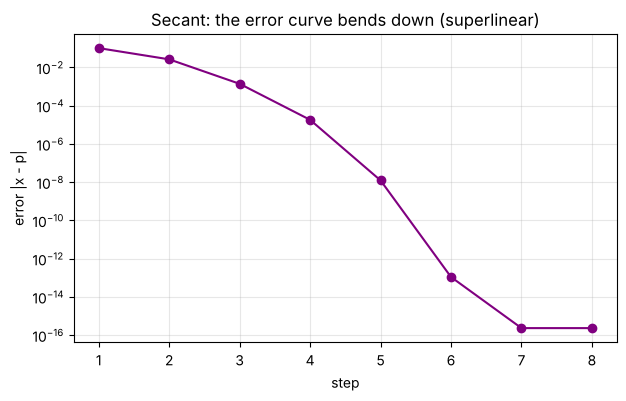

In [ ]:
p = 1.365230013414097
root, table = secant(f1, 1, 2, tol=1e-15, show=False)
errors = [abs(row[3] - p) + 1e-17 for row in table]
plt.figure(figsize=(7, 4))
plt.semilogy(range(1, len(errors) + 1), errors, "o-", color="purple")
plt.xlabel("step"); plt.ylabel("error |x - p|"); plt.grid(alpha=0.3)
plt.title("Secant: the error curve bends down (superlinear)"); plt.show()

## Step 11: The same method with a `while` loop
A `for` loop runs at most `max_iter` times and leaves early with `break`.
A `while` loop repeats **while** a condition is true. Here: while the two last answers are still far apart **and** we have not reached `max_iter`.

To start the loop we set `diff = tol + 1` (a number bigger than `tol`), so the condition is true the first time.

In [ ]:
def secant_while(f, x0, x1, tol=1e-6, max_iter=50, show=True):
    # same inputs and outputs as secant, but written with a while loop
    table = []                                     # one row for each step
    step = 0
    diff = tol + 1                                 # bigger than tol, so the loop starts

    while diff >= tol and step < max_iter:         # repeat WHILE not accurate enough
        step = step + 1
        f0, f1 = f(x0), f(x1)

        if f1 == f0:                               # horizontal secant line: cannot continue
            if show:
                print(f"Stopped at step {step}: f(x0) = f(x1) (horizontal secant line)")
            return None, table

        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)       # secant step
        diff = abs(x2 - x1)                        # change from the last answer
        table.append([step, x0, x1, x2, f(x2), diff])   # save this row
        x0, x1 = x1, x2                            # move forward: forget the oldest point

    if show:
        print_table(table)
        if diff < tol:
            print(f"Root = {x1:.10f}   (found in {step} steps)\n")
        else:
            print(f"WARNING: no convergence after {max_iter} steps. Last value = {x1}\n")

    return x1, table

Both versions give the **same** table and root:

In [ ]:
root, table = secant_while(f1, 1, 2)

 step          x_k-1            x_k          x_k+1     f(x_k+1)       |step|
----------------------------------------------------------------------------
    1   1.0000000000   2.0000000000   1.2631578947    -1.60e+00     7.37e-01
    2   2.0000000000   1.2631578947   1.3388278388    -4.30e-01     7.57e-02
    3   1.2631578947   1.3388278388   1.3666163947     2.29e-02     2.78e-02
    4   1.3388278388   1.3666163947   1.3652119026    -2.99e-04     1.40e-03
    5   1.3666163947   1.3652119026   1.3652300011    -2.03e-07     1.81e-05
    6   1.3652119026   1.3652300011   1.3652300134     1.80e-12     1.23e-08
----------------------------------------------------------------------------
Root = 1.3652300134   (found in 6 steps)



In [ ]:
r1, t1 = secant(f2, 0, 1, show=False)          # for loop
r2, t2 = secant_while(f2, 0, 1, show=False)    # while loop
print("for   loop:", r1, " steps:", len(t1))
print("while loop:", r2, " steps:", len(t2))

for   loop: 0.7390851332150012  steps: 5
while loop: 0.7390851332150012  steps: 5


**`for` or `while`?**

| | `for` loop | `while` loop |
|---|---|---|
| Repeats | at most `max_iter` times | while a condition is true |
| Stops early with | `break` | the condition becomes false |
| Needs a start value | no | yes: `diff = tol + 1` so the loop starts |
| Danger | none: it always ends | if the condition never becomes false the loop never ends, so we also check `step < max_iter` |

## Summary
| | Secant |
|---|---|
| Formula | $x_{k+1}=x_k-f(x_k)\dfrac{x_k-x_{k-1}}{f(x_k)-f(x_{k-1})}$ |
| Needs | $f$ and two starting guesses (no derivative, no sign change) |
| Stop when | $\lvert x_{k+1}-x_k\rvert<\text{tol}$ |
| Speed | superlinear, order $\approx1.618$ |
| Fails when | $f(x_k)=f(x_{k-1})$; bad starting points (divergence) |

| Method | Needs | Order | Always converges? |
|---|---|---|---|
| Bisection | sign change | 1 | yes |
| False position | sign change | 1 | yes |
| Fixed point | $x=g(x)$, $\lvert g'\rvert<1$ | 1 | no |
| **Newton** | $f'$ | 2 | no |
| **Secant** | two points | 1.618 | no |

## Your turn
Write `f(x)` and call `secant`.
1. $x^3-2x-5=0$, $\;x_0=2,\ x_1=3$ (answer about $2.0946$)
2. $x\ln x-1=0$, $\;x_0=1,\ x_1=2$ (answer about $1.7632$)
3. $e^{-x}-x=0$, $\;x_0=0,\ x_1=1$ (answer about $0.5671$)
4. Solve Exercise 1 with Newton too. Which method needs fewer **steps**? Fewer **function evaluations**?

In [ ]:
# write your code here